# Lung Cancer Level Prediction — Logistic Regression

**Author:** Miguel Estrada

## Objective
Train and evaluate a multiclass Logistic Regression model to predict the dataset's `Level` (`Low`, `Medium`, `High`) using the patient/risk-factor columns.

This notebook includes:
- Data inspection and basic quality checks
- Train/test split with stratification
- Preprocessing in a scikit-learn pipeline (to avoid leakage)
- Logistic Regression evaluation
- **Permutation importance for every original predictor column**
- **Class-specific coefficients for every model feature**, plus a summary at the original-column level

> **Important:** This is an educational modeling exercise, not a medical diagnostic tool. Predictions and feature importance are not clinical evidence of causation.

In [1]:
# Imports
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

## 1. Load the dataset

Place `cancer(1).csv` (or rename it to `cancer.csv`) in the same folder as this notebook.

In [2]:
# Find the dataset in the notebook's working directory
candidate_paths = [
    Path("cancer(1).csv"),
    Path("cancer.csv"),
]
data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "Dataset not found. Put 'cancer(1).csv' or 'cancer.csv' "
        "in the notebook's working directory."
    )

data = pd.read_csv(data_path)
print(f"Loaded: {data_path}")
print(f"Shape: {data.shape[0]:,} rows × {data.shape[1]} columns")
display(data.head())

Loaded: cancer.csv
Shape: 1,000 rows × 26 columns


,index,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,Obesity,Smoking,Passive Smoker,Chest Pain,Coughing of Blood,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
0,0,P1,33,1,2,4,5,4,3,2,2,4,3,2,2,4,3,4,2,2,3,1,2,3,4,Low
1,1,P10,17,1,3,1,5,3,4,2,2,2,2,4,2,3,1,3,7,8,6,2,1,7,2,Medium
2,2,P100,35,1,4,5,6,5,5,4,6,7,2,3,4,8,8,7,9,2,1,4,6,7,2,High
3,3,P1000,37,1,7,7,7,7,6,7,7,7,7,7,7,8,4,2,3,1,4,5,6,7,5,High
4,4,P101,46,1,6,8,7,7,7,6,7,7,8,7,7,9,3,2,4,1,4,2,4,2,3,High


## 2. Inspect data quality

In [3]:
display(data.info())

print("\\nMissing values by column:")
display(data.isna().sum().to_frame("Missing values"))

print(f"\\nExact duplicate rows: {data.duplicated().sum():,}")
print("\\nTarget distribution:")
display(data["Level"].value_counts(dropna=False).to_frame("Count"))
display((data["Level"].value_counts(normalize=True, dropna=False) * 100)
        .round(2).to_frame("Percentage"))

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   index                     1000 non-null   int64
 1   Patient Id                1000 non-null   str  
 2   Age                       1000 non-null   int64
 3   Gender                    1000 non-null   int64
 4   Air Pollution             1000 non-null   int64
 5   Alcohol use               1000 non-null   int64
 6   Dust Allergy              1000 non-null   int64
 7   OccuPational Hazards      1000 non-null   int64
 8   Genetic Risk              1000 non-null   int64
 9   chronic Lung Disease      1000 non-null   int64
 10  Balanced Diet             1000 non-null   int64
 11  Obesity                   1000 non-null   int64
 12  Smoking                   1000 non-null   int64
 13  Passive Smoker            1000 non-null   int64
 14  Chest Pain                1000 non-null   int64
 15 

None

\nMissing values by column:


,Missing values
index,0
Patient Id,0
Age,0
Gender,0
Air Pollution,0
Alcohol use,0
Dust Allergy,0
OccuPational Hazards,0
Genetic Risk,0
chronic Lung Disease,0


\nExact duplicate rows: 0
\nTarget distribution:


,Count
Level,
High,365
Medium,332
Low,303


,Percentage
Level,
High,36.5
Medium,33.2
Low,30.3


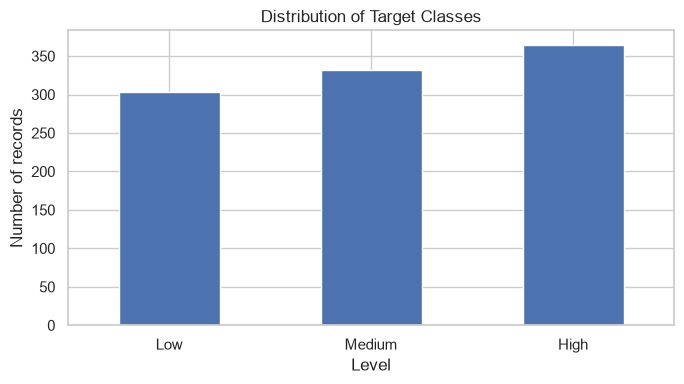

In [4]:
# Target distribution
target_counts = data["Level"].value_counts().reindex(["Low", "Medium", "High"])
target_counts.plot(kind="bar", figsize=(7, 4))
plt.title("Distribution of Target Classes")
plt.xlabel("Level")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 3. Prepare predictors and target

`Level` is the target. The `index` and `Patient Id` columns are identifiers, so they are excluded from the predictors: they identify records rather than describe a risk factor. All remaining predictor columns are included in the model.

Target encoding:
- `Low` → 0
- `Medium` → 1
- `High` → 2

In [5]:
target_mapping = {"Low": 0, "Medium": 1, "High": 2}
if data["Level"].isna().any():
    raise ValueError("The target column 'Level' contains missing values.")

unexpected_labels = set(data["Level"].unique()) - set(target_mapping)
if unexpected_labels:
    raise ValueError(f"Unexpected target labels: {unexpected_labels}")

y = data["Level"].map(target_mapping).astype(int)

identifier_columns = [col for col in ["index", "Patient Id"] if col in data.columns]
X = data.drop(columns=["Level"] + identifier_columns).copy()

print("Excluded identifier columns:", identifier_columns)
print(f"Predictor columns used ({X.shape[1]}):")
print(X.columns.tolist())
print("\\nTarget mapping:")
display(pd.DataFrame(
    [{"Original label": label, "Encoded value": code}
     for label, code in target_mapping.items()]
))

Excluded identifier columns: ['index', 'Patient Id']
Predictor columns used (23):
['Age', 'Gender', 'Air Pollution', 'Alcohol use', 'Dust Allergy', 'OccuPational Hazards', 'Genetic Risk', 'chronic Lung Disease', 'Balanced Diet', 'Obesity', 'Smoking', 'Passive Smoker', 'Chest Pain', 'Coughing of Blood', 'Fatigue', 'Weight Loss', 'Shortness of Breath', 'Wheezing', 'Swallowing Difficulty', 'Clubbing of Finger Nails', 'Frequent Cold', 'Dry Cough', 'Snoring']
\nTarget mapping:


,Original label,Encoded value
0,Low,0
1,Medium,1
2,High,2


In [6]:
# Stratified split keeps the class proportions similar in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print(f"Training samples: {len(X_train):,}")
print(f"Testing samples:  {len(X_test):,}")

Training samples: 800
Testing samples:  200


## 4. Preprocessing and Logistic Regression

In [7]:
# Detect feature types from predictor columns only
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first")),
])

transformers = []
if numeric_features:
    transformers.append(("numeric", numeric_pipeline, numeric_features))
if categorical_features:
    transformers.append(("categorical", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42,
    )),
])

model.fit(X_train, y_train)
print("Logistic Regression trained successfully.")
print("Model classes:", model.named_steps["classifier"].classes_)

Logistic Regression trained successfully.
Model classes: [0 1 2]


## 5. Model evaluation

In [8]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

evaluation = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced accuracy",
        "Precision (macro)",
        "Recall (macro)",
        "F1-score (macro)",
        "Precision (weighted)",
        "Recall (weighted)",
        "F1-score (weighted)",
        "ROC-AUC (OvR, macro)",
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        balanced_accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, average="macro", zero_division=0),
        recall_score(y_test, y_pred, average="macro", zero_division=0),
        f1_score(y_test, y_pred, average="macro", zero_division=0),
        precision_score(y_test, y_pred, average="weighted", zero_division=0),
        recall_score(y_test, y_pred, average="weighted", zero_division=0),
        f1_score(y_test, y_pred, average="weighted", zero_division=0),
        roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro"),
    ],
})
display(evaluation.round(4))

class_names = ["Low", "Medium", "High"]
print("\\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0,
))

,Metric,Score
0,Accuracy,1.0
1,Balanced accuracy,1.0
2,Precision (macro),1.0
3,Recall (macro),1.0
4,F1-score (macro),1.0
5,Precision (weighted),1.0
6,Recall (weighted),1.0
7,F1-score (weighted),1.0
8,"ROC-AUC (OvR, macro)",1.0


\nClassification report:
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00        61
      Medium       1.00      1.00      1.00        66
        High       1.00      1.00      1.00        73

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



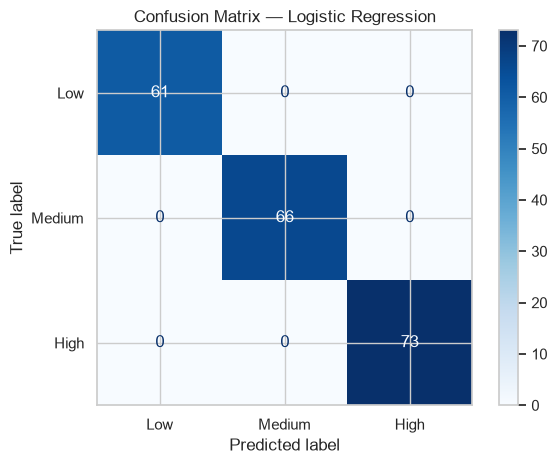

In [9]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
display_labels = ["Low", "Medium", "High"]

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_labels)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Logistic Regression")
plt.tight_layout()
plt.show()

## 6. Permutation importance — all original predictor columns

Permutation importance measures how much the selected evaluation score decreases when one input column is randomly shuffled. It is computed on the held-out test set using **macro F1**. The table includes every predictor column, including features with zero or negative measured importance.

This importance is model- and metric-dependent and describes predictive contribution, not causation.

In [10]:
perm_result = permutation_importance(
    estimator=model,
    X=X_test,
    y=y_test,
    scoring="f1_macro",
    n_repeats=30,
    random_state=42,
    n_jobs=-1,
)

permutation_table = pd.DataFrame({
    "Feature": X.columns,
    "Permutation importance (mean)": perm_result.importances_mean,
    "Permutation importance (std)": perm_result.importances_std,
}).sort_values("Permutation importance (mean)", ascending=False).reset_index(drop=True)

display(permutation_table.round(5))
print(f"Features included: {len(permutation_table)} / {X.shape[1]}")

,Feature,Permutation importance (mean),Permutation importance (std)
0,Wheezing,0.08077,0.01278
1,Obesity,0.06368,0.01295
2,Clubbing of Finger Nails,0.03072,0.00771
3,Snoring,0.01842,0.00791
4,Passive Smoker,0.01671,0.00610
5,Fatigue,0.01644,0.01001
6,Coughing of Blood,0.01519,0.00680
7,Dust Allergy,0.01154,0.00582
8,Swallowing Difficulty,0.01044,0.00629
9,Frequent Cold,0.00913,0.00638


Features included: 23 / 23


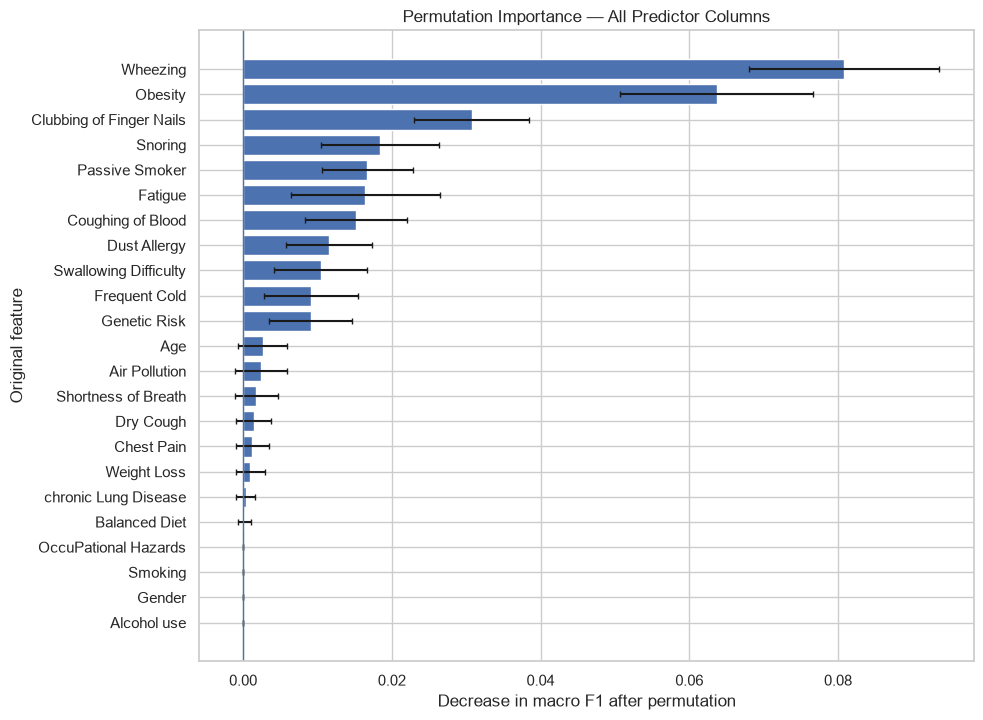

In [11]:
# Plot all predictor columns
plot_importance = permutation_table.sort_values(
    "Permutation importance (mean)", ascending=True
)

plt.figure(figsize=(10, max(6, len(plot_importance) * 0.32)))
plt.barh(
    plot_importance["Feature"],
    plot_importance["Permutation importance (mean)"],
    xerr=plot_importance["Permutation importance (std)"],
    capsize=2,
)
plt.axvline(0, linewidth=1)
plt.title("Permutation Importance — All Predictor Columns")
plt.xlabel("Decrease in macro F1 after permutation")
plt.ylabel("Original feature")
plt.tight_layout()
plt.show()

## 7. Logistic Regression coefficients — every encoded feature

The coefficient table contains one row for every feature after preprocessing and one coefficient for each class. Numeric predictors are standardized, so their coefficients represent a one-standard-deviation change in the predictor. Positive/negative signs indicate the direction of the class-specific model score, conditional on the other model features.

If categorical predictors are present, One-Hot Encoding creates separate coefficient rows for their non-reference categories.

In [12]:
fitted_preprocessor = model.named_steps["preprocessor"]
fitted_classifier = model.named_steps["classifier"]

encoded_feature_names = fitted_preprocessor.get_feature_names_out()
class_labels = {0: "Low", 1: "Medium", 2: "High"}

coefficient_table = pd.DataFrame({
    "Encoded feature": encoded_feature_names,
})

for class_index, class_code in enumerate(fitted_classifier.classes_):
    class_name = class_labels.get(int(class_code), str(class_code))
    coefficient_table[f"Coefficient ({class_name})"] = fitted_classifier.coef_[class_index]

class_coefficient_columns = [
    col for col in coefficient_table.columns if col.startswith("Coefficient (")
]
coefficient_table["Mean absolute coefficient"] = (
    coefficient_table[class_coefficient_columns].abs().mean(axis=1)
)
coefficient_table = coefficient_table.sort_values(
    "Mean absolute coefficient", ascending=False
).reset_index(drop=True)

display(coefficient_table.round(5))
print(f"Encoded coefficient rows: {len(coefficient_table)}")

,Encoded feature,Coefficient (Low),Coefficient (Medium),Coefficient (High),Mean absolute coefficient
0,numeric__Obesity,-1.64971,0.73889,0.91082,1.09981
1,numeric__Wheezing,-1.56723,1.25777,0.30946,1.04482
2,numeric__Passive Smoker,-1.42904,0.07058,1.35846,0.95270
3,numeric__Swallowing Difficulty,-1.30021,-0.07971,1.37993,0.91995
4,numeric__Clubbing of Finger Nails,-1.35241,0.59037,0.76204,0.90161
5,numeric__Coughing of Blood,-1.30545,-0.02662,1.33207,0.88805
6,numeric__Fatigue,-1.08301,-0.24898,1.33199,0.88799
7,numeric__Frequent Cold,-1.05171,0.34842,0.70328,0.70114
8,numeric__Snoring,-1.03166,0.56412,0.46754,0.68777
9,numeric__Air Pollution,-0.28325,-0.64603,0.92928,0.61952


Encoded coefficient rows: 23


## 8. Coefficient summary by original predictor column

This additional table maps encoded columns back to the original input predictors. It provides a row for **every original predictor column**, even if a categorical column expands into multiple encoded features. The summary is the mean absolute coefficient across encoded levels and classes; detailed signed coefficients remain available in the previous table.

In [13]:
def original_feature_name(encoded_name):
    # ColumnTransformer prefixes features with '<transformer>__'.
    name = encoded_name.split("__", 1)[-1]
    # Match the longest original feature name first, which helps with names containing underscores.
    for original_name in sorted(X.columns, key=len, reverse=True):
        if name == original_name or name.startswith(original_name + "_"):
            return original_name
    return name

coefficient_table["Original feature"] = coefficient_table["Encoded feature"].map(
    original_feature_name
)

coefficient_by_original = (
    coefficient_table.groupby("Original feature", as_index=False)
    .agg(
        **{
            "Encoded feature count": ("Encoded feature", "count"),
            "Mean absolute coefficient": ("Mean absolute coefficient", "mean"),
            "Maximum absolute coefficient": ("Mean absolute coefficient", "max"),
        }
    )
    .sort_values("Mean absolute coefficient", ascending=False)
    .reset_index(drop=True)
)

display(coefficient_by_original.round(5))
print(f"Original predictors represented: {coefficient_by_original['Original feature'].nunique()} / {X.shape[1]}")

,Original feature,Encoded feature count,Mean absolute coefficient,Maximum absolute coefficient
0,Obesity,1,1.09981,1.09981
1,Wheezing,1,1.04482,1.04482
2,Passive Smoker,1,0.95270,0.95270
3,Swallowing Difficulty,1,0.91995,0.91995
4,Clubbing of Finger Nails,1,0.90161,0.90161
5,Coughing of Blood,1,0.88805,0.88805
6,Fatigue,1,0.88799,0.88799
7,Frequent Cold,1,0.70114,0.70114
8,Snoring,1,0.68777,0.68777
9,Air Pollution,1,0.61952,0.61952


Original predictors represented: 23 / 23


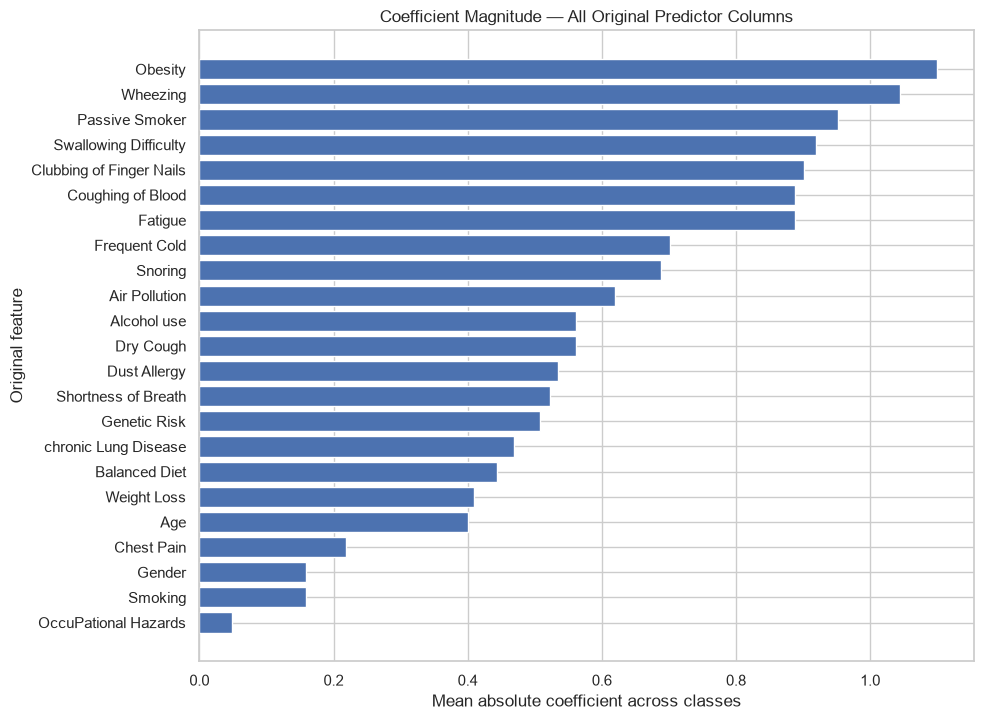

In [14]:
# Plot the coefficient magnitude summary for every original predictor
coef_plot = coefficient_by_original.sort_values(
    "Mean absolute coefficient", ascending=True
)

plt.figure(figsize=(10, max(6, len(coef_plot) * 0.32)))
plt.barh(coef_plot["Original feature"], coef_plot["Mean absolute coefficient"])
plt.title("Coefficient Magnitude — All Original Predictor Columns")
plt.xlabel("Mean absolute coefficient across classes")
plt.ylabel("Original feature")
plt.tight_layout()
plt.show()

## 9. Conclusions and limitations

Use the evaluation metrics, confusion matrix, permutation importance, and coefficient tables to describe the model.

- **Permutation importance** ranks original predictors by their impact on held-out macro F1.
- **Coefficients** show class-specific direction and magnitude in the fitted Logistic Regression model.
- Coefficient magnitudes and permutation importance are different measures and should not be treated as interchangeable.
- The dataset is observational and may contain simplified or synthetic relationships. Results may not generalize to real clinical populations.
- This model must not be used for medical diagnosis or treatment decisions.

**Project author:** Miguel Estrada

## 10. Encoding reference — original values and coded values

This final section places each categorical value beside its encoded value.

- The target `Level` is mapped as `Low → 0`, `Medium → 1`, and `High → 2`.
- If categorical predictor columns were One-Hot Encoded, the table shows each original category and the corresponding transformed column (or indicates the reference category when `drop="first"` is used).
- Numeric columns that already contain codes (such as `Gender` in this dataset) are listed separately with their observed values. Their underlying meanings are not inferred from the numbers.

In [15]:
# Target: original label beside its numeric code
target_encoding_reference = pd.DataFrame({
    "Column": ["Level"] * len(target_mapping),
    "Original value": list(target_mapping.keys()),
    "Coded value": list(target_mapping.values()),
    "Encoding": ["Target label mapping"] * len(target_mapping),
})
display(target_encoding_reference)

# Predictor categories that were encoded by the fitted OneHotEncoder
categorical_encoding_rows = []

if categorical_features:
    fitted_cat_pipeline = fitted_preprocessor.named_transformers_["categorical"]
    fitted_ohe = fitted_cat_pipeline.named_steps["onehot"]

    for feature, categories in zip(categorical_features, fitted_ohe.categories_):
        category_index = categorical_features.index(feature)
        dropped_index = (
            None if fitted_ohe.drop_idx_ is None
            else fitted_ohe.drop_idx_[category_index]
        )
        reference_value = None if dropped_index is None else categories[dropped_index]

        for category in categories:
            if category == reference_value:
                encoded_value = "Reference category (all dummy columns = 0)"
            else:
                encoded_value = f"categorical__{feature}_{category}"

            categorical_encoding_rows.append({
                "Column": feature,
                "Original value": category,
                "Coded value / transformed column": encoded_value,
                "Reference category": reference_value,
            })

if categorical_encoding_rows:
    categorical_encoding_reference = pd.DataFrame(categorical_encoding_rows)
    display(categorical_encoding_reference)
else:
    print("No categorical predictor columns were One-Hot Encoded in this dataset.")

# Numeric predictors that already contain discrete values/codes.
# These values were passed to the model as numeric, not newly encoded.
discrete_numeric_columns = [
    column for column in numeric_features
    if X[column].nunique(dropna=True) <= 10
]

already_numeric_rows = []
for column in discrete_numeric_columns:
    for value in sorted(X[column].dropna().unique().tolist()):
        already_numeric_rows.append({
            "Column": column,
            "Observed original value": value,
            "Value used by model": value,
            "Status": "Already numeric; no categorical encoding applied",
        })

if already_numeric_rows:
    already_numeric_reference = pd.DataFrame(already_numeric_rows)
    display(already_numeric_reference)
else:
    print("No low-cardinality numeric predictor columns found.")

,Column,Original value,Coded value,Encoding
0,Level,Low,0,Target label mapping
1,Level,Medium,1,Target label mapping
2,Level,High,2,Target label mapping


No categorical predictor columns were One-Hot Encoded in this dataset.


,Column,Observed original value,Value used by model,Status
0,Gender,1,1,Already numeric; no categorical encoding applied
1,Gender,2,2,Already numeric; no categorical encoding applied
2,Air Pollution,1,1,Already numeric; no categorical encoding applied
3,Air Pollution,2,2,Already numeric; no categorical encoding applied
4,Air Pollution,3,3,Already numeric; no categorical encoding applied
...,...,...,...,...
161,Snoring,3,3,Already numeric; no categorical encoding applied
162,Snoring,4,4,Already numeric; no categorical encoding applied
163,Snoring,5,5,Already numeric; no categorical encoding applied
164,Snoring,6,6,Already numeric; no categorical encoding applied
